In [1]:
# Cell 1: Imports, Setup, and Helper Functions
from pathlib import Path
import json
import shutil
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
import optuna
from optuna.visualization import plot_pareto_front
import gc
import spatial_split as ss
from spatial_split import load_year_split

# 1. Directories and Global Constants
data_base_dir = Path('data/regionwise_yearwise_samples')
artifact_dir = Path('data/feature_selection_artifacts')
output_config_dir = Path('data/optuna_regional_gee_configs')
output_config_dir.mkdir(parents=True, exist_ok=True)

# TARGET_REGIONS = ['DES', 'IGP', 'WGR', 'ICR'] 
# TARGET_REGIONS = ['IGP', 'WGR', 'ICR'] 

TARGET_REGIONS = ['PEN', 'WGR', 'IGP', 'ICR', 'DES', 'NEI']
import os
# TARGET_REGIONS = os.environ.get('REGIONS', 'HIM').split(',')
N_TRIALS = int(os.environ.get('N_TRIALS', 60))
RF_JOBS = int(os.environ.get('RF_JOBS', 2))   # cores used by each random forest fit (results do not depend on it)
SAMPLER_SEED = 0
N_STARTUP = 15                    # random trials before TPE starts guiding
# search years per region come from 03_split_and_years.ipynb (ss.search_years(region))
print('optuna', optuna.__version__)

# 2. Class Remapping
old_codes = [5, 3, 4, 12, 11, 66, 19, 36, 9, 41, 24, 23, 75, 30, 25, 33, 76, 34, 61]
new_codes = [5, 3, 4, 12, 11, 66, 19, 14, 14, 14, 22, 22, 22, 22, 22, 33, 76, 34, 61]
class_remap_dict = dict(zip(old_codes, new_codes))

# 3. Reference Balancing Setup
ref_csv_path = Path('data/classwise_samples_reference_ratios.csv')
ref_df = pd.read_csv(ref_csv_path)
ref_df['old_code'] = old_codes
ref_df['new_code'] = new_codes
ref_region_cols = [c for c in ref_df.columns if c not in ['l2_code', 'l2_name', 'l1_parent', 'old_code', 'new_code']]
parent_ref_df = ref_df.groupby('new_code')[ref_region_cols].sum()

def get_balanced_indices(y_train_arr, target_n, ref_series, rng):
    classes = np.unique(y_train_arr)
    col_present = ref_series.reindex(classes).fillna(0.0)
    scaled = (np.sqrt(col_present) / sum(np.sqrt(col_present))) * target_n
    selected = []
    for cls in classes:
        cls_idx = np.where(y_train_arr == cls)[0]
        desired = int(np.round(scaled.get(cls, 0)))
        n_sample = min(len(cls_idx), max(3, desired))
        selected.extend(rng.choice(cls_idx, size=n_sample, replace=False))
    return np.array(selected)

optuna 4.9.0



🚀 STARTING PIPELINE FOR REGION: PEN

[PEN] Loaded 103 ranked features, 36 uncorrelated features.
[PEN] Search years: [2000, 2003, 2006, 2009, 2014, 2016, 2019, 2022, 2025]
[PEN] Loading and caching benchmark years...
2000  Train: 81.35%  Val: 15.41%  Test: 3.24%
2003  Train: 82.34%  Val: 14.35%  Test: 3.30%
2006  Train: 81.67%  Val: 14.64%  Test: 3.69%
2009  Train: 81.72%  Val: 14.72%  Test: 3.56%
2014  Train: 81.77%  Val: 14.47%  Test: 3.75%
2016  Train: 81.87%  Val: 14.46%  Test: 3.67%
2019  Train: 81.73%  Val: 14.45%  Test: 3.82%
2022  Train: 81.75%  Val: 14.43%  Test: 3.81%
2025  Train: 81.73%  Val: 14.43%  Test: 3.84%
[PEN] classes: [3, 4, 5, 11, 12, 14, 19, 22, 33, 66, 76]

[PEN] Executing Optuna Study...


[I 2026-10-29 00:11:06,509] A new study created in RDB with name: rf_PEN


[PEN] 0 trials already complete; running 60 more


[I 2026-10-29 00:12:46,465] Trial 0 finished with values: [0.6605598335186155, 338161967850.0] and parameters: {'sampling_strategy': 'reference_balanced', 'feature_strategy': 'all', 'max_input_features': 49, 'train_fraction': 0.7000000000000001, 'minLeafPopulation': 6, 'numberOfTrees': 150}.
[I 2026-10-29 00:13:47,730] Trial 1 finished with values: [0.7814978291156474, 632909242350.0] and parameters: {'sampling_strategy': 'stratified', 'feature_strategy': 'all', 'max_input_features': 63, 'train_fraction': 0.9, 'minLeafPopulation': 2, 'numberOfTrees': 50}.
[I 2026-10-29 00:14:40,878] Trial 2 finished with values: [0.6582937392066216, 166866069600.0] and parameters: {'sampling_strategy': 'reference_balanced', 'feature_strategy': 'uncorrelated', 'train_fraction': 0.9, 'minLeafPopulation': 10, 'numberOfTrees': 100}.
[I 2026-10-29 00:15:35,544] Trial 3 finished with values: [0.7551446285041437, 315036001350.0] and parameters: {'sampling_strategy': 'stratified', 'feature_strategy': 'all', 'm


[PEN] Generating Pareto Html...


[PEN] Exporting Trial Data to CSV/JSON...


/tmp/ipykernel_48228/2414131248.py:163: Pandas4Warning: The default 'epoch' date format is deprecated and will be removed in a future version, please use 'iso' date format instead.
  df_all_trials.to_json(output_config_dir / f"{region}_all_trials.json", orient="records", indent=4)


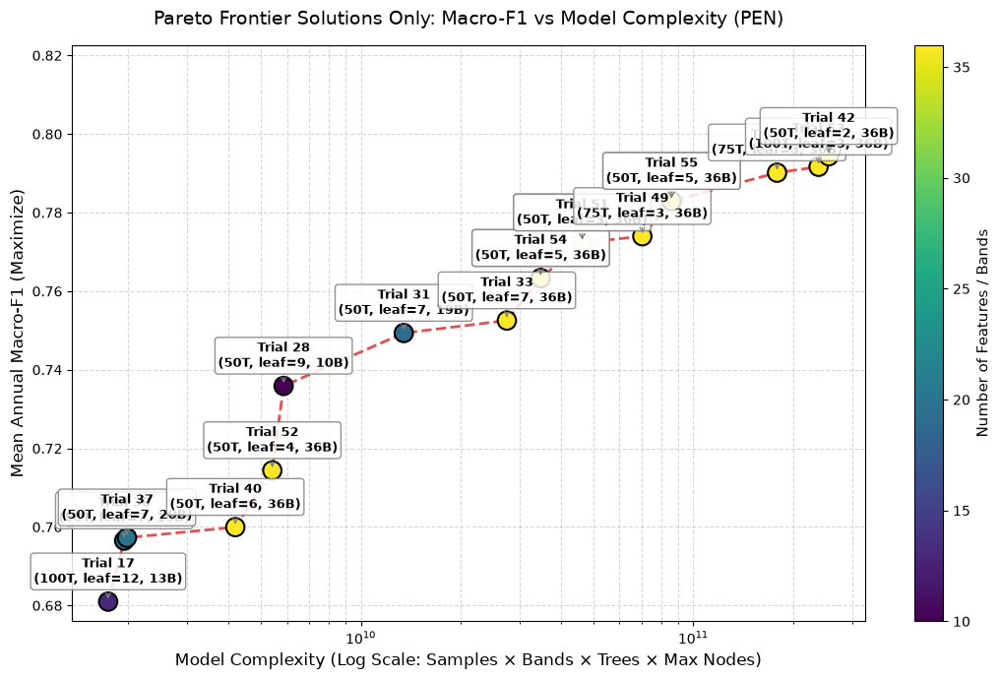


=== Pareto-Optimal Candidates Table for PEN ===
 trial_number  macro_f1  f1_min_year  model_complexity  samples_per_year  num_features  trees  min_leaf feature_strat   sampling
           17  0.680988     0.635153      1.738667e+09              4596            13    100        12           all stratified
           38  0.696524     0.650588      1.942959e+09              4596            19     50         7           all stratified
           37  0.697267     0.654108      1.980876e+09              4596            20     50         7           all stratified
           40  0.699956     0.606349      4.194310e+09              4596            36     50         6  uncorrelated stratified
           52  0.714380     0.619839      5.418684e+09              4596            36     50         4  uncorrelated stratified
           28  0.735893     0.681684      5.859374e+09             13803            10     50         9           all stratified
           31  0.749356     0.723509      1.3466

[I 2026-10-29 00:46:40,581] A new study created in RDB with name: rf_WGR


[WGR] 0 trials already complete; running 60 more


[I 2026-10-29 00:48:28,067] Trial 0 finished with values: [0.6299324256630895, 451628055900.0] and parameters: {'sampling_strategy': 'reference_balanced', 'feature_strategy': 'all', 'max_input_features': 49, 'train_fraction': 0.7000000000000001, 'minLeafPopulation': 6, 'numberOfTrees': 150}.
[I 2026-10-29 00:49:25,172] Trial 1 finished with values: [0.7047869454640288, 516845504700.0] and parameters: {'sampling_strategy': 'stratified', 'feature_strategy': 'all', 'max_input_features': 63, 'train_fraction': 0.9, 'minLeafPopulation': 2, 'numberOfTrees': 50}.
[I 2026-10-29 00:50:13,855] Trial 2 finished with values: [0.6107226235250219, 204566899000.0] and parameters: {'sampling_strategy': 'reference_balanced', 'feature_strategy': 'uncorrelated', 'train_fraction': 0.9, 'minLeafPopulation': 10, 'numberOfTrees': 100}.
[I 2026-10-29 00:51:06,430] Trial 3 finished with values: [0.6805370405143326, 308209784400.0] and parameters: {'sampling_strategy': 'stratified', 'feature_strategy': 'all', 'm


[WGR] Generating Pareto Html...


[WGR] Exporting Trial Data to CSV/JSON...


/tmp/ipykernel_48228/2414131248.py:163: Pandas4Warning: The default 'epoch' date format is deprecated and will be removed in a future version, please use 'iso' date format instead.
  df_all_trials.to_json(output_config_dir / f"{region}_all_trials.json", orient="records", indent=4)


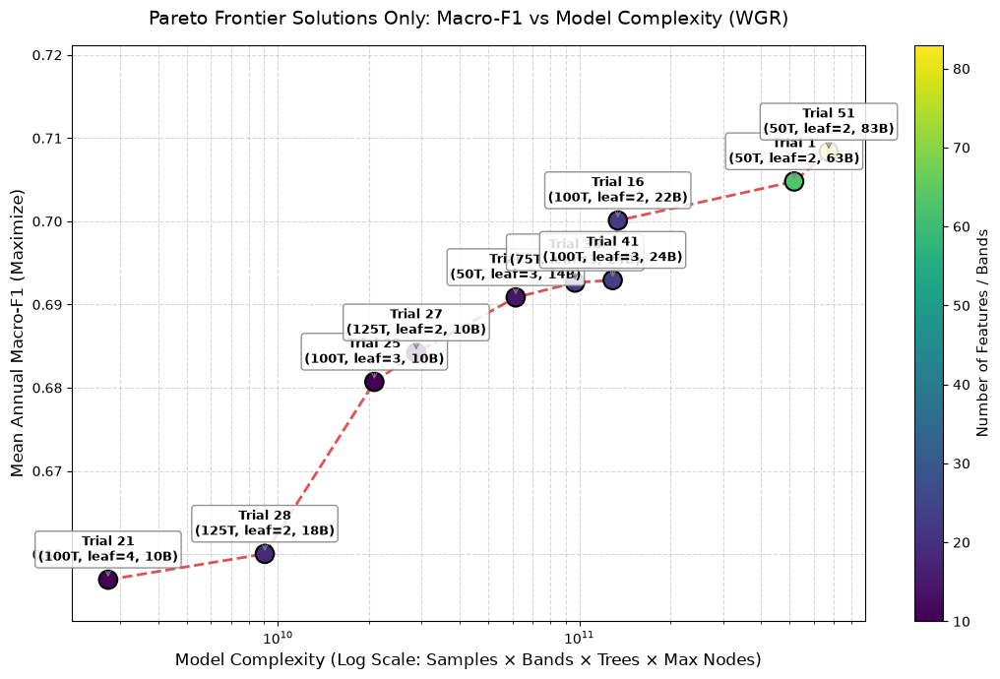


=== Pareto-Optimal Candidates Table for WGR ===
 trial_number  macro_f1  f1_min_year  model_complexity  samples_per_year  num_features  trees  min_leaf feature_strat   sampling
           21  0.656925     0.604766      2.731652e+09              5068            10    100         4           all stratified
           28  0.660027     0.601791      9.042579e+09              5068            18    125         2           all stratified
           25  0.680700     0.626618      2.089294e+10             15217            10    100         3           all stratified
           27  0.684217     0.632583      2.877915e+10             15217            10    125         2           all stratified
           57  0.690857     0.625543      6.153147e+10             35516            14     50         3           all stratified
           38  0.692631     0.643485      9.684995e+10             25368            24     75         3           all stratified
           41  0.692937     0.646087      1.2913

[I 2026-10-29 01:30:16,858] A new study created in RDB with name: rf_IGP


[IGP] classes: [3, 4, 11, 12, 14, 19, 22, 33, 66, 76]

[IGP] Executing Optuna Study...
[IGP] 0 trials already complete; running 60 more


[I 2026-10-29 01:32:27,705] Trial 0 finished with values: [0.7476419464650936, 497112942900.0] and parameters: {'sampling_strategy': 'reference_balanced', 'feature_strategy': 'all', 'max_input_features': 49, 'train_fraction': 0.7000000000000001, 'minLeafPopulation': 6, 'numberOfTrees': 150}.
[I 2026-10-29 01:33:47,627] Trial 1 finished with values: [0.7528836566537344, 809312288400.0] and parameters: {'sampling_strategy': 'stratified', 'feature_strategy': 'all', 'max_input_features': 63, 'train_fraction': 0.9, 'minLeafPopulation': 2, 'numberOfTrees': 50}.
[I 2026-10-29 01:34:48,524] Trial 2 finished with values: [0.7475033299378814, 287124652500.0] and parameters: {'sampling_strategy': 'reference_balanced', 'feature_strategy': 'uncorrelated', 'train_fraction': 0.9, 'minLeafPopulation': 10, 'numberOfTrees': 100}.
[I 2026-10-29 01:36:03,694] Trial 3 finished with values: [0.7378355049059728, 438972392250.0] and parameters: {'sampling_strategy': 'stratified', 'feature_strategy': 'all', 'm


[IGP] Generating Pareto Html...


[IGP] Exporting Trial Data to CSV/JSON...


/tmp/ipykernel_48228/2414131248.py:163: Pandas4Warning: The default 'epoch' date format is deprecated and will be removed in a future version, please use 'iso' date format instead.
  df_all_trials.to_json(output_config_dir / f"{region}_all_trials.json", orient="records", indent=4)


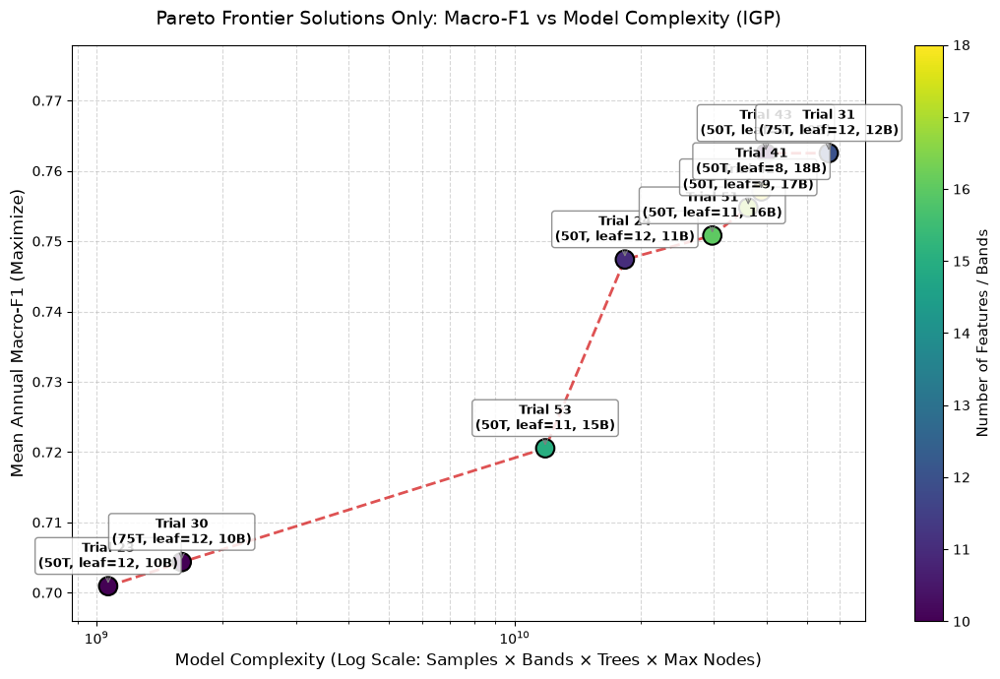


=== Pareto-Optimal Candidates Table for IGP ===
 trial_number  macro_f1  f1_min_year  model_complexity  samples_per_year  num_features  trees  min_leaf feature_strat   sampling
           23  0.700924     0.610859      1.065577e+09              6598            10     50        12           all stratified
           30  0.704349     0.615630      1.598366e+09              6598            10     75        12           all stratified
           53  0.720539     0.672657      1.183904e+10             19806            15     50        11           all stratified
           24  0.747392     0.672865      1.835799e+10             33015            11     50        12           all stratified
           51  0.750801     0.681723      2.971350e+10             33015            16     50        11           all stratified
           42  0.754789     0.683061      3.622901e+10             33015            17     50         9           all stratified
           41  0.757080     0.694358      3.8954

[I 2026-10-29 02:15:56,418] A new study created in RDB with name: rf_ICR


[ICR] 0 trials already complete; running 60 more


[I 2026-10-29 02:18:18,670] Trial 0 finished with values: [0.7235012801387096, 521260971000.0] and parameters: {'sampling_strategy': 'reference_balanced', 'feature_strategy': 'all', 'max_input_features': 49, 'train_fraction': 0.7000000000000001, 'minLeafPopulation': 6, 'numberOfTrees': 150}.
[I 2026-10-29 02:19:43,189] Trial 1 finished with values: [0.723715933131446, 648646472250.0] and parameters: {'sampling_strategy': 'stratified', 'feature_strategy': 'all', 'max_input_features': 63, 'train_fraction': 0.9, 'minLeafPopulation': 2, 'numberOfTrees': 50}.
[I 2026-10-29 02:21:01,347] Trial 2 finished with values: [0.7671607866075214, 333462248400.0] and parameters: {'sampling_strategy': 'reference_balanced', 'feature_strategy': 'uncorrelated', 'train_fraction': 0.9, 'minLeafPopulation': 10, 'numberOfTrees': 100}.
[I 2026-10-29 02:22:20,841] Trial 3 finished with values: [0.697584760162234, 405299675550.0] and parameters: {'sampling_strategy': 'stratified', 'feature_strategy': 'all', 'max


[ICR] Generating Pareto Html...


[ICR] Exporting Trial Data to CSV/JSON...


/tmp/ipykernel_48228/2414131248.py:163: Pandas4Warning: The default 'epoch' date format is deprecated and will be removed in a future version, please use 'iso' date format instead.
  df_all_trials.to_json(output_config_dir / f"{region}_all_trials.json", orient="records", indent=4)


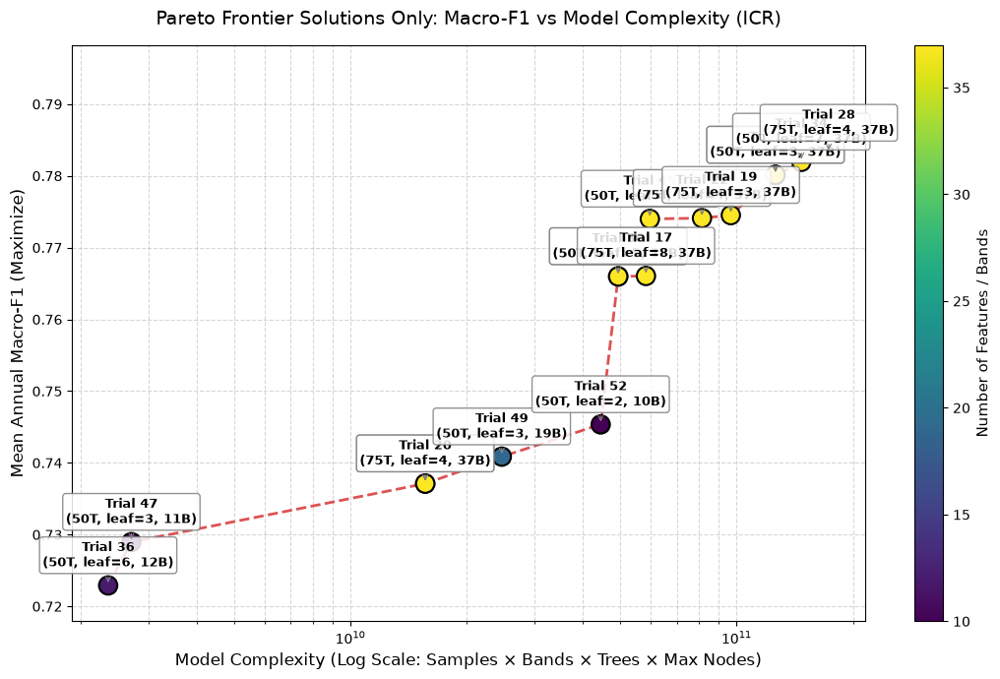


=== Pareto-Optimal Candidates Table for ICR ===
 trial_number  macro_f1  f1_min_year  model_complexity  samples_per_year  num_features  trees  min_leaf feature_strat           sampling
           36  0.722920     0.656215      2.357026e+09              6904            12     50         6           all reference_balanced
           47  0.728965     0.678014      2.707404e+09              6904            11     50         3           all reference_balanced
           18  0.737112     0.667429      1.561426e+10              6904            37     75         4  uncorrelated reference_balanced
           20  0.737112     0.667429      1.561426e+10              6904            37     75         4  uncorrelated reference_balanced
           49  0.740871     0.672394      2.465002e+10             19093            19     50         3           all reference_balanced
           52  0.745355     0.693944      4.445265e+10             40876            10     50         2           all reference_b

[I 2026-10-29 03:01:20,861] A new study created in RDB with name: rf_DES


[DES] 0 trials already complete; running 60 more


[I 2026-10-29 03:04:06,402] Trial 0 finished with values: [0.47286155166424, 831179924400.0] and parameters: {'sampling_strategy': 'reference_balanced', 'feature_strategy': 'all', 'max_input_features': 49, 'train_fraction': 0.7000000000000001, 'minLeafPopulation': 6, 'numberOfTrees': 150}.
[I 2026-10-29 03:05:43,491] Trial 1 finished with values: [0.5412375721012915, 1186234355250.0] and parameters: {'sampling_strategy': 'stratified', 'feature_strategy': 'all', 'max_input_features': 63, 'train_fraction': 0.9, 'minLeafPopulation': 2, 'numberOfTrees': 50}.
[I 2026-10-29 03:07:05,879] Trial 2 finished with values: [0.4633033519808552, 397206864000.0] and parameters: {'sampling_strategy': 'reference_balanced', 'feature_strategy': 'uncorrelated', 'train_fraction': 0.9, 'minLeafPopulation': 10, 'numberOfTrees': 100}.
[I 2026-10-29 03:08:41,555] Trial 3 finished with values: [0.5215135511756923, 722354692500.0] and parameters: {'sampling_strategy': 'stratified', 'feature_strategy': 'all', 'ma


[DES] Generating Pareto Html...


[DES] Exporting Trial Data to CSV/JSON...


/tmp/ipykernel_48228/2414131248.py:163: Pandas4Warning: The default 'epoch' date format is deprecated and will be removed in a future version, please use 'iso' date format instead.
  df_all_trials.to_json(output_config_dir / f"{region}_all_trials.json", orient="records", indent=4)


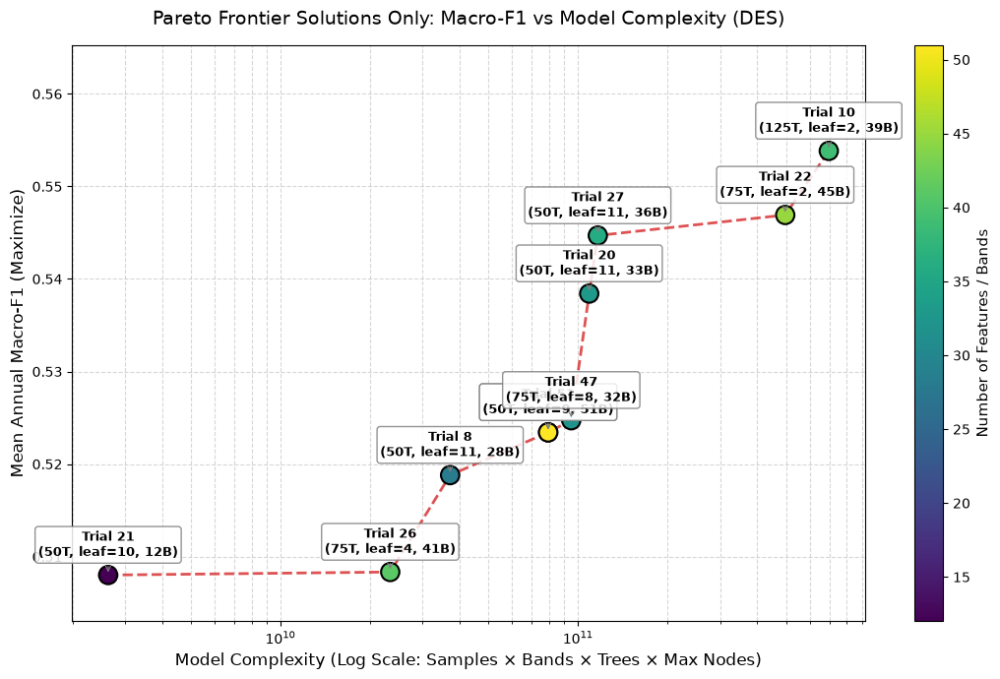


=== Pareto-Optimal Candidates Table for DES ===
 trial_number  macro_f1  f1_min_year  model_complexity  samples_per_year  num_features  trees  min_leaf feature_strat   sampling
           21  0.508006     0.411712      2.633796e+09              8868            12     50        10           all stratified
           26  0.508334     0.428447      2.336962e+10              8868            41     75         4           all stratified
            8  0.518804     0.427688      3.715340e+10             26618            28     50        11           all stratified
           43  0.523425     0.424540      7.934693e+10             26618            51     50         9           all stratified
           51  0.523425     0.424540      7.934693e+10             26618            51     50         9           all stratified
           47  0.524733     0.429724      9.486655e+10             26618            32     75         8  uncorrelated stratified
           20  0.538422     0.444110      1.0901

[I 2026-10-29 04:09:41,881] A new study created in RDB with name: rf_NEI


[NEI] 0 trials already complete; running 60 more


[I 2026-10-29 04:14:05,855] Trial 0 finished with values: [0.7634682499841084, 1992056829000.0] and parameters: {'sampling_strategy': 'reference_balanced', 'feature_strategy': 'all', 'max_input_features': 49, 'train_fraction': 0.7000000000000001, 'minLeafPopulation': 6, 'numberOfTrees': 150}.
[I 2026-10-29 04:16:31,367] Trial 1 finished with values: [0.7579870458196343, 2658936136500.0] and parameters: {'sampling_strategy': 'stratified', 'feature_strategy': 'all', 'max_input_features': 63, 'train_fraction': 0.9, 'minLeafPopulation': 2, 'numberOfTrees': 50}.
[I 2026-10-29 04:18:53,878] Trial 2 finished with values: [0.7367904809544136, 1155829969400.0] and parameters: {'sampling_strategy': 'reference_balanced', 'feature_strategy': 'uncorrelated', 'train_fraction': 0.9, 'minLeafPopulation': 10, 'numberOfTrees': 100}.
[I 2026-10-29 04:21:16,019] Trial 3 finished with values: [0.7463013238209688, 1489484092950.0] and parameters: {'sampling_strategy': 'stratified', 'feature_strategy': 'all'


[NEI] Generating Pareto Html...


[NEI] Exporting Trial Data to CSV/JSON...


/tmp/ipykernel_48228/2414131248.py:163: Pandas4Warning: The default 'epoch' date format is deprecated and will be removed in a future version, please use 'iso' date format instead.
  df_all_trials.to_json(output_config_dir / f"{region}_all_trials.json", orient="records", indent=4)


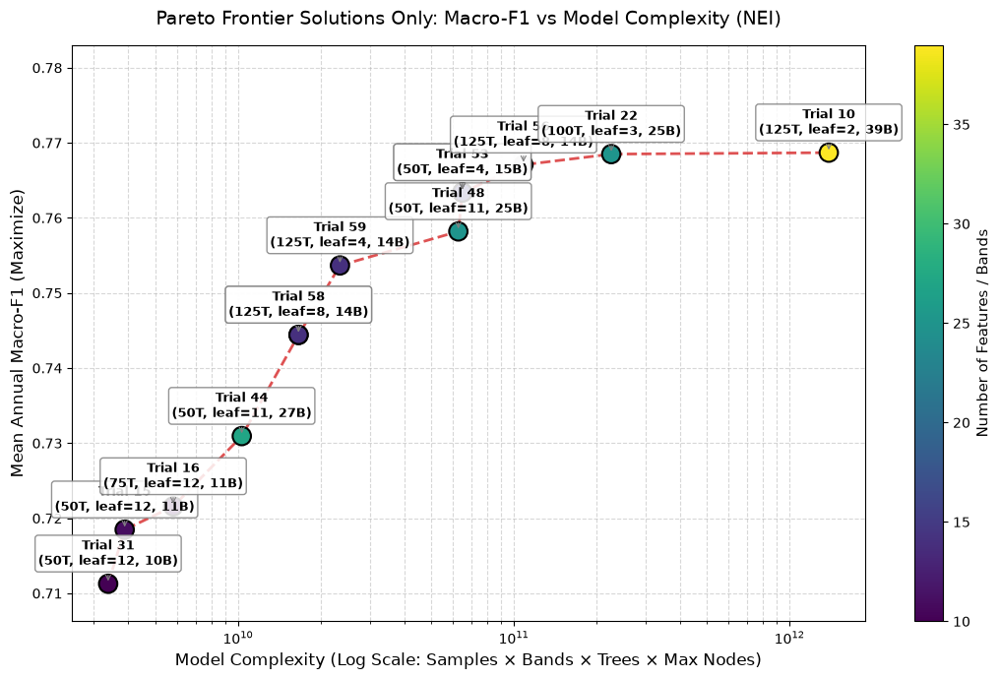


=== Pareto-Optimal Candidates Table for NEI ===
 trial_number  macro_f1  f1_min_year  model_complexity  samples_per_year  num_features  trees  min_leaf feature_strat           sampling
           31  0.711268     0.634569      3.376930e+09             11313            10     50        12           all reference_balanced
           15  0.718472     0.653755      3.876399e+09             11313            11     50        12           all reference_balanced
           16  0.721572     0.653375      5.814599e+09             11313            11     75        12           all reference_balanced
           44  0.730940     0.670887      1.030897e+10             11313            27     50        11           all reference_balanced
           57  0.744417     0.663233      1.656046e+10             11306            14    125         8           all         stratified
           58  0.744417     0.663233      1.656046e+10             11306            14    125         8           all         str

In [2]:
# Cell 2: Master Pipeline (Data Prep -> Optuna -> Plotting -> Export)
for region in TARGET_REGIONS:
    print(f"\n{'='*70}")
    print(f"🚀 STARTING PIPELINE FOR REGION: {region}")
    print(f"{'='*70}\n")
    # --- STEP 1: Load Features ---
    with open(artifact_dir / f"{region}_ranked_features.json", "r") as f:
        all_ranked = json.load(f)["ranked_features"]
    with open(artifact_dir / f"{region}_uncorrelated_features.json", "r") as f:
        uncorr_ranked = json.load(f)["uncorrelated_features"]
    
    print(f"[{region}] Loaded {len(all_ranked)} ranked features, {len(uncorr_ranked)} uncorrelated features.")
    BENCHMARK_YEARS = ss.search_years(region)
    print(f"[{region}] Search years: {BENCHMARK_YEARS}")

    # --- STEP 2: Pre-Partition Data ---
    print(f"[{region}] Loading and caching benchmark years...")
    region_dir = data_base_dir / region
    cache_dir = Path(f'data/cache_splits_{region}')
    
    if cache_dir.exists():
        shutil.rmtree(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    
    region_labels = set()
    for yr in BENCHMARK_YEARS:
        sp = load_year_split(region, yr, all_ranked, gated=True)
        X_train, y_train = sp['train']
        X_val, y_val = sp['val']
        X_test, y_test = sp['test']

        region_labels |= set(np.unique(y_train)) | set(np.unique(y_val)) | set(np.unique(y_test))
        total_samples = len(X_train) + len(X_val) + len(X_test)
        print(f"{yr}  Train: {len(X_train)/total_samples:.2%}  "
              f"Val: {len(X_val)/total_samples:.2%}  Test: {len(X_test)/total_samples:.2%}")

        np.savez_compressed(cache_dir / f"split_{yr}.npz", X_tr=X_train, y_tr=y_train,
                            X_val=X_val, y_val=y_val, X_test=X_test, y_test=y_test)
        del X_train, y_train, X_val, y_val, X_test, y_test, sp
        gc.collect()

    region_labels = sorted(int(v) for v in region_labels)
    print(f"[{region}] classes: {region_labels}")

    # --- STEP 3: Optuna Optimization ---
    print(f"\n[{region}] Executing Optuna Study...")
    feat_to_idx = {name: i for i, name in enumerate(all_ranked)}
    ref_col_series = parent_ref_df[region] if region in parent_ref_df.columns else None

    def objective(trial):
        sampling_strategy = trial.suggest_categorical("sampling_strategy", ["stratified", "reference_balanced"])
        feat_strategy = trial.suggest_categorical("feature_strategy", ["all", "uncorrelated"])
        
        if feat_strategy == "uncorrelated":
            active_names = uncorr_ranked
        else:
            num_bands = trial.suggest_int("max_input_features", 10, len(all_ranked))
            active_names = all_ranked[:num_bands]
            
        active_col_idx = [feat_to_idx[f] for f in active_names]
        train_fraction = trial.suggest_float("train_fraction", 0.10, 0.90, step=0.20)
        min_leaf = trial.suggest_int("minLeafPopulation", 2, 12)
        n_trees = trial.suggest_int("numberOfTrees", 50, 150, step=25)

        rf_params = {
            "n_estimators": n_trees, "min_samples_leaf": min_leaf,
            "max_features": "sqrt", "max_depth": None,
            "n_jobs": RF_JOBS, "random_state": 42
        }

        yearly_macro_f1s = []
        annual_training_sample_counts = []
        all_year_max_nodes = []
        per_year = {}
        rng = np.random.RandomState(42)

        for yr in BENCHMARK_YEARS:
            data = np.load(cache_dir / f"split_{yr}.npz")
            X_tr, y_tr, X_val, y_val = data['X_tr'], data['y_tr'], data['X_val'][:, active_col_idx], data['y_val']
            target_n = int(len(X_tr) * train_fraction)

            if train_fraction >= 0.99 and sampling_strategy == "stratified":
                chosen_local = np.arange(len(X_tr))
            elif sampling_strategy == "reference_balanced" and ref_col_series is not None:
                chosen_local = get_balanced_indices(y_tr, target_n, ref_col_series, rng)
            else:
                chosen_local = []
                for cls in np.unique(y_tr):
                    cls_indices = np.where(y_tr == cls)[0]
                    n_take = max(3, int(target_n * len(cls_indices) / len(y_tr)))
                    chosen_local.extend(rng.choice(cls_indices, size=min(len(cls_indices), n_take), replace=False))
                chosen_local = np.array(chosen_local)

            annual_training_sample_counts.append(len(chosen_local))
            X_sub, y_sub = X_tr[chosen_local][:, active_col_idx], y_tr[chosen_local]

            clf = RandomForestClassifier(**rf_params)
            clf.fit(X_sub, y_sub)

            all_year_max_nodes.append(max(tree.tree_.node_count for tree in clf.estimators_))
            pred = clf.predict(X_val)
            f1m = f1_score(y_val, pred, average="macro")
            yearly_macro_f1s.append(f1m)
            per_year[int(yr)] = {
                "macro_f1": float(f1m),
                "f1_per_class": [float(v) for v in f1_score(y_val, pred, labels=region_labels, average=None, zero_division=0)],
                "confusion": confusion_matrix(y_val, pred, labels=region_labels).tolist(),
                "n_train": int(len(chosen_local)), "n_val": int(len(y_val)),
            }

            del data, X_tr, y_tr, X_val, y_val, X_sub, y_sub, clf
            gc.collect()

        mean_macro_f1 = float(np.mean(yearly_macro_f1s))
        samples_per_year = int(np.mean(annual_training_sample_counts))
        max_nodes_observed = int(max(all_year_max_nodes))
        num_features = len(active_col_idx)
        single_model_complexity = float(samples_per_year * num_features * n_trees * max_nodes_observed)

        trial.set_user_attr("samples_per_year", samples_per_year)
        trial.set_user_attr("num_features", num_features)
        trial.set_user_attr("max_nodes", max_nodes_observed)
        trial.set_user_attr("model_complexity", single_model_complexity)
        trial.set_user_attr("f1_min_year", float(np.min(yearly_macro_f1s)))
        trial.set_user_attr("f1_sd_years", float(np.std(yearly_macro_f1s)))
        trial.set_user_attr("labels", region_labels)
        trial.set_user_attr("per_year", per_year)

        return mean_macro_f1, single_model_complexity

    # Standard in-memory study
    sampler = optuna.samplers.TPESampler(seed=SAMPLER_SEED, n_startup_trials=N_STARTUP)
    # stored on disk so an interrupted run resumes where it stopped (delete the .db to start a region from scratch)
    study = optuna.create_study(
        study_name=f"rf_{region}",
        directions=["maximize", "minimize"],
        sampler=sampler,
        storage=f"sqlite:///{output_config_dir}/{region}_study.db",
        load_if_exists=True,
    )
    n_done = sum(t.state.name == "COMPLETE" for t in study.trials)
    print(f"[{region}] {n_done} trials already complete; running {max(0, N_TRIALS - n_done)} more")
    study.optimize(objective, n_trials=max(0, N_TRIALS - n_done), n_jobs=1)

    # --- STEP 4: Plotly Visualization ---
    print(f"\n[{region}] Generating Pareto Html...")
    fig_plotly = plot_pareto_front(study, target_names=["Mean Macro-F1", "Model Complexity"])
    fig_plotly.update_layout(title=f"Multi-Objective Pareto Front (F1 vs Model Complexity) - {region}", width=900, height=550)
    fig_plotly.write_html(output_config_dir / f"{region}_pareto_frontier.html")
    fig_plotly.show()

    # --- STEP 5: Data Export ---
    print(f"[{region}] Exporting Trial Data to CSV/JSON...")
    # full per-year metrics (macro-F1, per-class F1, confusion matrices) for every trial
    per_year_dump = [{"trial": t.number, "params": t.params, "values": list(t.values) if t.values else None,
                      "labels": t.user_attrs.get("labels"), "per_year": t.user_attrs.get("per_year")}
                     for t in study.trials if t.values is not None]
    with open(output_config_dir / f"{region}_per_year_metrics.json", "w") as f:
        json.dump({"region": region, "search_years": BENCHMARK_YEARS, "trials": per_year_dump}, f)
    df_all_trials = study.trials_dataframe()
    df_all_trials = df_all_trials.drop(columns=[c for c in df_all_trials.columns if c in ("user_attrs_per_year", "user_attrs_labels")])
    df_all_trials.to_csv(output_config_dir / f"{region}_all_trials.csv", index=False)
    df_all_trials.to_json(output_config_dir / f"{region}_all_trials.json", orient="records", indent=4)

    # --- STEP 6: Matplotlib Custom Pareto Analysis ---
    pareto_records = []
    for t in study.best_trials:
        strat = t.params.get("feature_strategy", "all")
        n_feats = len(uncorr_ranked) if strat == "uncorrelated" else t.params.get("max_input_features", len(all_ranked))
            
        pareto_records.append({
            "trial_number": t.number,
            "macro_f1": float(t.values[0]),
            "model_complexity": float(t.values[1]),
            "samples_per_year": t.user_attrs.get("samples_per_year"),
            "num_features": t.user_attrs.get("num_features", n_feats),
            "max_nodes": t.user_attrs.get("max_nodes"),
            "trees": t.params.get("numberOfTrees"),
            "min_leaf": t.params.get("minLeafPopulation"),
            "sampling": t.params.get("sampling_strategy"),
            "feature_strat": strat,
            "train_fraction": t.params.get("train_fraction"),
            "f1_min_year": t.user_attrs.get("f1_min_year"),
            "f1_sd_years": t.user_attrs.get("f1_sd_years")
        })

    if pareto_records:
        df_pareto = pd.DataFrame(pareto_records).sort_values("model_complexity")
        df_pareto.to_csv(output_config_dir / f"{region}_pareto_frontier.csv", index=False)
        df_pareto.to_json(output_config_dir / f"{region}_pareto_frontier.json", orient="records", indent=4)

        fig, ax = plt.subplots(figsize=(11, 7))
        ax.plot(df_pareto["model_complexity"], df_pareto["macro_f1"], color="#d62728", linestyle="--", linewidth=2, alpha=0.8, zorder=2, label="Pareto Efficient Frontier")
        scatter = ax.scatter(df_pareto["model_complexity"], df_pareto["macro_f1"], c=df_pareto["num_features"], cmap="viridis", s=180, edgecolor="black", linewidth=1.5, zorder=3)
        
        cbar = plt.colorbar(scatter, ax=ax)
        cbar.set_label("Number of Features / Bands", fontsize=11)

        for _, row in df_pareto.iterrows():
            label_text = f"Trial {int(row['trial_number'])}\n({int(row['trees'])}T, leaf={int(row['min_leaf'])}, {int(row['num_features'])}B)"
            ax.annotate(
                label_text, xy=(row["model_complexity"], row["macro_f1"]), xytext=(0, 14), textcoords="offset points",
                ha="center", fontsize=9, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="gray", alpha=0.85),
                arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0", color="gray", lw=0.8)
            )

        ax.set_xscale("log")
        ax.set_title(f"Pareto Frontier Solutions Only: Macro-F1 vs Model Complexity ({region})", fontsize=14, pad=15)
        ax.set_xlabel("Model Complexity (Log Scale: Samples × Bands × Trees × Max Nodes)", fontsize=12)
        ax.set_ylabel("Mean Annual Macro-F1 (Maximize)", fontsize=12)
        ax.grid(True, which="both", linestyle="--", alpha=0.5)

        y_margin = (df_pareto["macro_f1"].max() - df_pareto["macro_f1"].min()) * 0.25
        ax.set_ylim(df_pareto["macro_f1"].min() - 0.005, df_pareto["macro_f1"].max() + y_margin)

        plt.tight_layout()
        plt.savefig(output_config_dir / f"{region}_pareto_only_frontier.png", dpi=300, bbox_inches="tight")
        plt.show()

        print(f"\n=== Pareto-Optimal Candidates Table for {region} ===")
        display_cols = ["trial_number", "macro_f1", "f1_min_year", "model_complexity", "samples_per_year", "num_features", "trees", "min_leaf", "feature_strat", "sampling"]
        print(df_pareto[display_cols].to_string(index=False))

    print(f"\n[{region}] Pipeline Complete!\n")
    gc.collect()